In [4]:
# Importing essential libraries for mathematical simulations and visualizations
import random
import numpy as np
import matplotlib.pyplot as plt

# Set a random seed for reproducibility.
random.seed(42)
np.random.seed(42)

# Game, Set, Math!!! # 
## or Simulating the Probability of Winning a Tennis Game 

### Section 1: Introduction

Both of my kids train in tennis professionally (practicing every day, doing specialized fitness, and playing tournaments). Because of this, I want this project to be not only a math assignment but also a practical, psychological lesson for them. 

At children's tournaments, you often see kids get very emotional over a single lost point. They feel like they need to be perfect and completely overpower their opponent. But is that mathematically true? How does a slight physical or tactical edge in a single rally translate to a definitive victory in a game, a set, or a match?

To answer this, we will translate a real-life tennis match into a mathematical model. We can treat each rally (a point played) as a **random event**, where each outcome happens with a certain probability. Because it is not possible to predict the exact outcome of the next rally, we will treat the result of a single point as a **random variable**.

**The Core Concept:**
If two equal players meet on the court, they each have a 50% chance of winning any given point. What is mind-blowing is that even the Greatest of All Time, Novak Djokovic, won only about 54% of his total points throughout his entire career.[1] The exact same 54% statistic applies to other tennis legends in history, such as Rafael Nadal and Roger Federer. You don't need to win every ball to become a legend.[2,3]

**Our Goal:**
My goal is to demonstrate mathematically and computationally (including to my kids) that you do not need to be "head and shoulders" above your opponent. By just accumulating a micro-advantage in individual random events (e.g., improving your point-winning probability from 50% to just 55%), you guarantee a massive statistical advantage over the course of a whole game.

So now let's see if, a player has a slight advantage—for example, a 55% chance of winning any given point—how much does that increase their overall probability of winning the game? 


### Section 2: Mathematical Foundation

To understand how a tiny advantage turns into a game win, we need to map the rules of tennis into a mathematical structure. In tennis, the score progresses in discrete steps: 0 (Love), 15, 30, 40, and Game. So the temporarely result in a game can be different, let me give you a few examples:
* 15-15 (both players won by one point)
* 40-30 (first player won 3 points and second player won 2 points)
* 40-40 - is called deuce, where both players now should win at least 2 points to win the game, if the first player wins a point it becomes A-40 (A-from advantage), so now the 1st player needs only one point to win the game, the 2nd player now needs 3 points to win the game. 

To solve the combinatorial problem of counting all possible scores, we use a graphic method called a **tree diagram**[4]. We start at a score of 0-0. Every time a point is played, the "tree" branches into two possible paths:
1. Player A wins the point (with probability $p$)
2. Player B wins the point (with probability $1-p$)

By drawing all intermediate results (e.g., 15-0, 15-15, 30-15) and the links between them, we can see that a specific "path" through the tree represents one possible outcome of the game. 

#### The Algebra of Events
"The Multiplication Rule is used to find the probability of two or more events occurring together (simultaneously or in sequence). The formula depends on whether the events are independent or dependent."[5] Because each rally is an independent random event, we can calculate the probability of a specific path using the multiplication rule for independent events: $P(A \cap B) = P(A) \times P(B)$.

For example, what is the probability of a player winning a "perfect game" (winning 4 points in a row without dropping one)? We simply multiply the probability of winning a single point ($p$) four times along that specific path:
$P(\text{Win at Love}) = p \times p \times p \times p = p^4$

Let's look at the math:
* If $p = 0.50$ (50%), the chance of a perfect game is $0.50^4 = 0.0625$ (or **6.25%**).
* If $p = 0.55$ (55%), the chance of a perfect game is $0.55^4 \approx 0.0915$ (or **9.15%**). 

*Notice the math magic here: just a 5% improvement in winning a single rally leads to an almost 50% relative increase in the chance of winning a perfect game!*

#### A Note on Mathematical Assumptions

Is a tennis rally truly an independent event in real life? Not completely. At a score of 0-40, a player (especially a young one) might feel immense psychological pressure, fatigue, or a loss of momentum. 

However, in mathematical modeling, we must explicitly state our assumptions and simplifications. For this simulation, we treat every point as a strictly **independent random event**. In our simulation, we assign a constant probability $p$ (e.g., 55%) to every single point. Mathematically, this assumes that both players perform at the exact same level of physical and mental intensity throughout the entire game. But taking this approach isn't just a mathematical convenience—it is a winning mindset. 

The Big Three (Djokovic, Nadal, and Federer) have proven time and time again that even at the most critical moments (like facing a match point or a break point), you can still play as if it is just an ordinary point. As Roger Federer famously said in his 2024 commencement address: 
> *"When you’re playing a point, it is the most important thing in the world. But when it’s behind you, it’s behind you... This mindset is really crucial, because it frees you to fully commit to the next point… and the next one after that… with intensity, clarity and focus."* [6]

So, this mathematical simplification doubles as a powerful psychological lesson for young players: if you can mentally "reset" after a lost point and treat the next rally as a completely independent statistical event, your past mistakes hold no power over your future probabilities.

#### A Note on Mathematical Assumptions
Is a tennis rally truly an independent event in real life? Not completely. At a score of 0-40, a player(especially kids) might feel immense psychological pressure, fatigue, or a loss of momentum. 

However, in mathematical modeling, we must explicitly state our assumptions and simplifications. For this simulation, we treat every point as a strictly independent random event. At the same time, it's not just assumption and simplification, because the Big Three (Djokovic, Nadal and Federer) have proved 100 times that at the important points(when your oponent has a match point or a break point), you can still play as if it's just an ordinary point. Roger Federer in 2024 said: "When you’re playing a point, it is the most important thing in the world.
But when it’s behind you, it’s behind you... This mindset is really crucial, because it frees you to fully commit to the next point… and the next one after that… with intensity, clarity and focus."[6] So this is not just a mathematical simplification, but it's a powerful psychological lesson for young players: if you can mentally "reset" after a lost point and treat the next rally as a completely independent statistical event, your past mistakes hold no power over your future probabilities. 

#### The "Deuce" Problem
While calculating a direct path like $p^4$ is easy, a real tennis game is much more complex. Players drop points, and if the score reaches 40-40 (Deuce), a player must win by two clear points. 

Because of this "win by two" rule, the tree diagram becomes infinite—the game could theoretically go on forever! Calculating every single infinite combinatorial path manually using algebra is exhausting. To solve this, we will move from theoretical math to computational simulation.

### Section 3: Python Simulation & Random Variables
We will write a Python function to simulate the rallies. Every point is a **random variable**, meaning it is not possible to predict the exact next outcome. 

Because we cannot predict a single game's outcome, we will run the same experiment thousands of times (trials). We will then calculate the empirical frequency of winning the game as $f_i = \frac{m_i}{n}$, where $m_i$ is the number of games won, and $n$ is the total number of simulated games. As $n$ increases, this empirical frequency stabilizes around the true theoretical probability.

In [34]:
def simulate_single_game(p):
    """
    Simulates a single tennis game.
    p: probability of Player A winning a single point (e.g., 0.55)
    Returns: True if Player A wins the game, False if Player B wins.
    Note: In this internal logic, scores are represented as points (0, 1, 2, 3) rather than tennis terms (0, 15, 30, 40).

    """
    score_a = 0
    score_b = 0
    
    # A player wins the game if they score at least 4 points AND have a margin of at least 2 points
    # it also resolves the deuce situation by continuing until one player has a 2-point lead after reaching 4 points.
    while not (score_a >= 4 and score_a - score_b >= 2) and \
          not (score_b >= 4 and score_b - score_a >= 2):
        
        # Random event: simulating a single rally
        # random.random() generates a number between 0.0 and 1.0
        if random.random() < p:
            score_a += 1
        else:
            score_b += 1
            
    return score_a > score_b

def simulate_multiple_games(p, n_trials=10000):
    """
    Simulates n_trials games to find the empirical probability of winning.
    p: probability of winning a single point
    n_trials: number of games to simulate
    
    Returns:
    - empirical_prob (float): The final frequency of games won (m / n).
    - win_rates (list): History of win rates at each trial step for plotting.
    """    
    games_won = 0
    win_rates = [] # To track the probability stabilizing over time
    
    for i in range(1, n_trials + 1):
        if simulate_single_game(p):
            games_won += 1
            
        # Calculate frequency f_i = m_i / n at each step
        win_rates.append(games_won / i)
        
    return games_won / n_trials, win_rates

# Let's test it with a 55% chance of winning a single point (micro-advantage)
p_point = 0.55
empirical_prob, history = simulate_multiple_games(p_point, n_trials=10000)

print(f"Probability of winning a single point: {p_point*100:.1f}%")
print(f"Empirical probability of winning the GAME: {empirical_prob*100:.1f}%")

Probability of winning a single point: 55.0%
Empirical probability of winning the GAME: 62.1%


### Section 4: Analysis & Visualization

Now that we have built our computational model, we can analyze the results visually. We will explore two fundamental statistical phenomena:

#### 1. The Law of Large Numbers (LLN)
"The law of large numbers has a very central role in probability and statistics. It states that if you repeat an experiment independently a large number of times and average the result, what you obtain should be close to the expected value."[7] So if we only simulate 10 or 20 games, luck plays a massive role—a player with a 55% edge might lose most of them. However, as we run thousands of trials, the randomness evens out, and the mathematical truth emerges. We can visualize this random variable by plotting its value against the trial number:


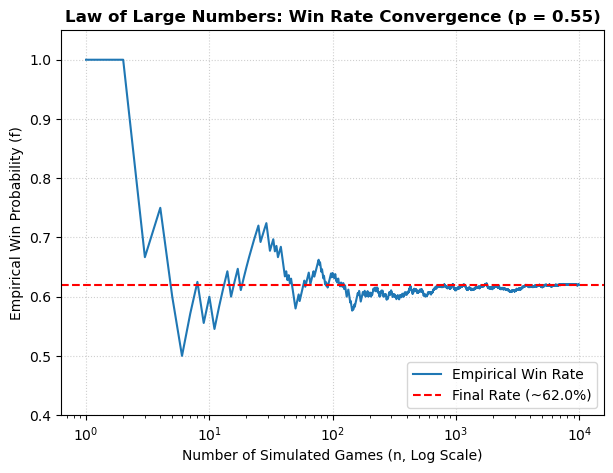

In [24]:
fig, ax1 = plt.subplots(figsize=(7, 5))

# Plot 1: Law of Large Numbers (Convergence)
trials_history = np.arange(1, len(history) + 1)
ax1.plot(trials_history, history, color='#1f77b4', linewidth=1.5, label='Empirical Win Rate')
ax1.axhline(y=empirical_prob, color='r', linestyle='--', label=f'Final Rate (~{empirical_prob*100:.1f}%)')
ax1.set_xscale('log') # Log scale helps highlight initial fluctuations vs long-term stability
ax1.set_title('Law of Large Numbers: Win Rate Convergence (p = 0.55)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Simulated Games (n, Log Scale)', fontsize=10)
ax1.set_ylabel('Empirical Win Probability (f)', fontsize=10)
ax1.set_ylim(0.4, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right')
plt.show()

From the previous plot we see that as the number of trials ($n$) increases, the empirical frequency of an outcome ($f = \frac{m}{n}$) converges to its theoretical probability.We can see that in the first 10-100 games, the line is highly volatile—luck dominates. But as the number of simulated games reaches 1,000 to 10,000, the line flattens out perfectly, converging on the theoretical probability. This proves that while single random events are unpredictable, large samples follow strict mathematical laws.

#### 2. The Micro-Advantage Amplification Curve
What happens when we vary the point-winning probability ($p$) from 40% to 60%? By plotting the overall game-winning probability against the point-winning probability, we can see the non-linear leverage of tennis scoring. 

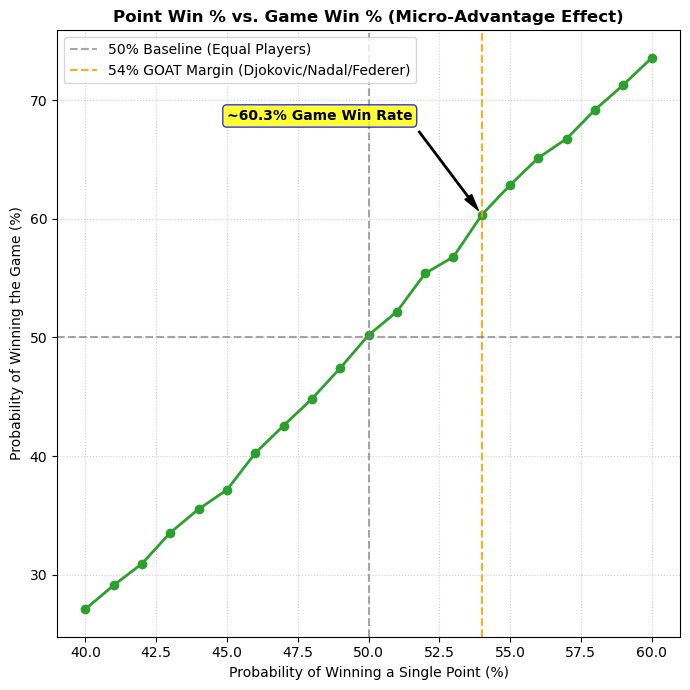

In [ ]:
fig, ax2 = plt.subplots(figsize=(7, 7))

# Plot 2: Micro-Advantage Amplification Curve
p_values = np.linspace(0.40, 0.60, 21)
game_win_rates = []

for p_val in p_values:
    win_rate, _ = simulate_multiple_games(p_val, n_trials=10000)
    game_win_rates.append(win_rate)

ax2.plot(p_values * 100, np.array(game_win_rates) * 100, marker='o', color='#2ca02c', linewidth=2)
ax2.axvline(x=50, color='gray', linestyle='--', alpha=0.7, label='50% Baseline (Equal Players)')
ax2.axvline(x=54, color='orange', linestyle='--', alpha=0.9, label='54% GOAT Margin (Djokovic/Nadal/Federer)')
ax2.axhline(y=50, color='gray', linestyle='--', alpha=0.7)

# Annotate the GOAT point on the graph
goat_game_win = game_win_rates[np.argmin(np.abs(p_values - 0.54))] * 100
ax2.annotate(f'~{goat_game_win:.1f}% Game Win Rate', 
             xy=(54, goat_game_win), 
             xytext=(45, goat_game_win + 8),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="b", lw=1, alpha=0.8))

ax2.set_title('Point Win % vs. Game Win % (Micro-Advantage Effect)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Probability of Winning a Single Point (%)', fontsize=10)
ax2.set_ylabel('Probability of Winning the Game (%)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

This graph shows the massive leverage hidden in tennis scoring. If two equal players meet (50% point win rate), the game win rate is exactly 50%. However, an increase to just **54%** (the historic margin of Djokovic, Nadal, and Federer) skyrockets the game-winning probability to **60.3%**! A 55% edge pushes it past 62%. And 60% gives us over **74%** of the game-winning probability!

### Section 5: The Power of Every Point

" 1/3 = 100% 
This equation may not seem correct. It isn’t correct to a mathematician but for high-level tennis players it most certainly is accurate."[8] According to the article Dynamic Win Probability of The Rossetti Brothers "If you are up 40-LOVE, then all you need to do is win 33% of the remaining points or one of the next three points and you will win the game 100% of the time."

What happens if a player wins the very first point of the game (making the score 15-0)? Does the probability of winning the game change? 

In probability theory, this is called **Conditional Probability**. We want to find the probability of winning the game given that the first point is already won and how in general the probabiblity is changed depending on different results in the game. 
Let's calculate the conditional probability of winning a game for an **equal player** ($p=0.50$) from various starting scores and see if our simulation matches the theoretical math!

In [38]:
def simulate_game_from_score(p, start_score_a, start_score_b):
    """
    Simulates a game starting from a specific point score.
    Note: In this internal logic, scores are represented as points (0, 1, 2, 3) 
    rather than tennis terms (0, 15, 30, 40).
    """
    score_a = start_score_a 
    score_b = start_score_b
    
    while not (score_a >= 4 and score_a - score_b >= 2) and \
          not (score_b >= 4 and score_b - score_a >= 2):
        
        if random.random() < p:
            score_a += 1
        else:
            score_b += 1
            
    return score_a > score_b

def get_conditional_win_rate(p, start_a, start_b, trials=100000):
    games_won = sum(simulate_game_from_score(p, start_a, start_b) for _ in range(trials))
    return games_won / trials

# We will test an EQUAL player (p = 0.50) from different starting scenarios
p_equal = 0.50

# Defining scenarios: (A's points, B's points, "Tennis Score String")
scenarios = [
    (0, 0, "0-0 (Love-All)"),
    (1, 0, "15-0"),
    (1, 1, "15-15"),
    (2, 0, "30-0"),
    (3, 0, "40-0"),
    (0, 1, "0-15"),
    (2, 2, "30-30"),
    (3, 3, "40-40 (Deuce)")
]

print(f"--- Conditional Game Win Probabilities (p = {p_equal}) ---")
for points_a, points_b, score_str in scenarios:
    win_rate = get_conditional_win_rate(p_equal, points_a, points_b)
    print(f"From score {score_str:<15}: {win_rate*100:.1f}%")



--- Conditional Game Win Probabilities (p = 0.5) ---
From score 0-0 (Love-All) : 50.1%
From score 15-0           : 65.7%
From score 15-15          : 50.0%
From score 30-0           : 81.5%
From score 40-0           : 93.7%
From score 0-15           : 34.4%
From score 30-30          : 49.9%
From score 40-40 (Deuce)  : 50.0%


### Section 4: Conclusion

### Section 5: References 

1. Novak Djokovic's stats ATP page: https://www.atptour.com/en/players/novak-djokovic/d643/player-stats?year=all&surface=all
2. Rafael Nadal's stats ATP page: https://www.atptour.com/en/players/rafael-nadal/n409/player-stats?year=all&surface=all
3. Roger Federer's stats ATP page: https://www.atptour.com/en/players/roger-federer/f324/player-stats?year=all&surface=all
4. Tree diagram: https://en.wikipedia.org/wiki/Tree_diagram_(probability_theory)
5. Probability Formulas: https://www.geeksforgeeks.org/maths/probability-formulas/
6. 2024 Commencement Address by Roger Federer: https://home.dartmouth.edu/news/2024/06/2024-commencement-address-roger-federer
7. Law of Large Numbers: https://www.probabilitycourse.com/chapter7/7_1_1_law_of_large_numbers.php
8. Dynamic Win Probability: https://tennacity.org/2018/11/23/dynamic-win-probability/

